##### 1. Prepare a dataset suitable for fine-tuning a GPT model on a specific task of your choice.

● Select a task (e.g., text classification, sentiment analysis, question-answering).

● Collect and preprocess a dataset for the selected task (ensure it is properly
cleaned, tokenized, and encoded).

● Provide a written report (500-700 words) detailing the dataset preparation
process, including the source of the data and the preprocessing steps taken.

##### 2. Fine-tune a GPT model on the prepared dataset and evaluate its performance.

● Fine-tune a pre-trained GPT model on the dataset using Hugging Face
Transformers.

● Evaluate the model's performance using appropriate metrics (e.g., accuracy,
precision, recall, F1 score).

● Write a detailed report (800-1000 words) documenting the fine-tuning process,
the model's performance, and any challenges faced.

##### I followed the huggingface LLM Course

In [1]:
# importing the necessary libraries
from transformers import pipeline

In [2]:
import torch
print(f"GPU Available: {torch.cuda.is_available()}")
print(f"GPU Name: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'N/A'}")

GPU Available: True
GPU Name: Tesla T4


In [3]:
classifier = pipeline("sentiment-analysis")
classifier("I love reading")

No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9996932744979858}]

In [4]:
classifier.model.config.name_or_path

'distilbert/distilbert-base-uncased-finetuned-sst-2-english'

##### passing different sentences

In [5]:
classifier(["I love reading romance books", "I hate self help books  "])

[{'label': 'POSITIVE', 'score': 0.9991010427474976},
 {'label': 'NEGATIVE', 'score': 0.9991851449012756}]

### Pipelines for different modalities

#####  1. Zero-shot classification

In [6]:
classifier = pipeline("zero-shot-classification")
classifier("I love playing pool", candidate_labels=["sports", "politics", "business"])


No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

{'sequence': 'I love playing pool',
 'labels': ['sports', 'business', 'politics'],
 'scores': [0.9893578290939331, 0.006892664358019829, 0.0037494725547730923]}

##### 2. Text generation

In [7]:
generator = pipeline("text-generation")
generator("I like reading because")

No model was supplied, defaulted to openai-community/gpt2 and revision 607a30d.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: openai-community/gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

... (2 outputs left out)

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Both `max_new_tokens` (=256) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': 'I like reading because it\'s about learning from each other and being friends. When I was growing up, I read a lot of books on romance, and I was like "I really like reading this." I was like "What do you mean?" and it was something my friends used to do.\n\nWhat was it like growing up?\n\nWhen I was growing up, I was a little shy in the way that I was in school. I was like "Oh yeah, I know, I\'m a little shy." Like, I was shy when I was growing up. So it was like, "Oh, I guess I\'m going to have to learn to be a little more careful."\n\nDo you have any advice for kids and teens who are curious about romance?\n\nI think that\'s one of the things I think about when I\'m in the early stages of my career. I think that if you\'re really into it when you\'re in high school, then you\'re a little nervous. And if you\'re really into it when you\'re in college, then you\'re a little nervous. But I think that\'s kind of where I\'m at.\n\nSo what do you think of young people

##### using models from hub in a pipeline

In [8]:
generator = pipeline("text-generation", model="HuggingFaceTB/SmolLM2-360M")
generator("I love reading because", max_length=30, num_return_sequences=2)


config.json:   0%|          | 0.00/689 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/724M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/831 [00:00<?, ?B/s]

Passing `generation_config` together with generation-related arguments=({'num_return_sequences', 'max_length'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Setting `pad_token_id` to `eos_token_id`:0 for open-end generation.
Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': "I love reading because it allows me to learn and grow. I think the author's perspective helps me to understand that life in a small town is not always filled with hardships and people who are as they were when they were young. I do not think the author is trying to tell us to never leave our little town but rather to realize that life can always take a turn for the better. I have always been around kids who were constantly making fun of me and I have always felt like they are a threat to me. I have learned over time that they are not. They are just kids and they will grow into adults and will have a variety of different opinions and views. I know for sure that I will never be a kid again and my life will never be the same.\n\n\nI could definitely relate to the article because, like the author, I have been in a small town for so long that I have grown to appreciate it. I grew up there and the only way I could understand it was by reading about it and meeting people 

In [9]:
generator = pipeline("text-generation", model="openai-community/gpt2")
generator("I love reading because", max_length=30, num_return_sequences=2)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: openai-community/gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.
Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': 'I love reading because I can find out if I\'m being overly critical or dismissive of the book. To me, this is a much better book than the "great book" that was "just" "just" "just" a little over a year ago.\n\nAs a critic, I\'ve been an admirer of this book, but I can\'t say I have found it any more intellectually challenging than it was before. I\'d love to read a second or third book that I can actually agree with about the book.\n\nThe main issue as I read this book, and as I\'ve said several times before, is that it\'s just another book, and I don\'t know if I want to read another one. I\'m not sure if I want to read a third book that I\'ve already heard about, but at the same time, I\'m not sure if I want to read "another" or in the same order as this book. And I\'m not sure what I\'m going to do with that second book.\n\nThe second book, in other words, is more of a mixed bag of things, but that\'s not the point. The point is that these are very good books, a

##### mask filling

In [10]:
unmasker = pipeline("fill-mask")
unmasker("I love reading because it makes me <mask> alive.", top_k=3)


No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/331M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

RobertaForMaskedLM LOAD REPORT from: distilbert/distilroberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

[{'score': 0.9480993747711182,
  'token': 619,
  'token_str': ' feel',
  'sequence': 'I love reading because it makes me feel alive.'},
 {'score': 0.021319076418876648,
  'token': 283,
  'token_str': ' come',
  'sequence': 'I love reading because it makes me come alive.'},
 {'score': 0.01140320673584938,
  'token': 1095,
  'token_str': ' stay',
  'sequence': 'I love reading because it makes me stay alive.'}]

##### Named entity recognition

In [11]:
ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Bernice and I work at Really Great Tech in Ghana.")

No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.33G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9987641),
  'word': 'Bernice',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.99764746),
  'word': 'Really Great Tech',
  'start': 33,
  'end': 50},
 {'entity_group': 'LOC',
  'score': np.float32(0.9997652),
  'word': 'Ghana',
  'start': 54,
  'end': 59}]

##### Question answering

In [12]:
question_answerer = pipeline("question-answering")
question_answerer(
    question="Where does I work?",
    context="My name is Bernice and I work at Really Great Tech in Ghana."
)



No model was supplied, defaulted to distilbert/distilbert-base-cased-distilled-squad and revision 564e9b5.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/473 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/261M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

{'score': 0.5985625982284546,
 'start': 33,
 'end': 59,
 'answer': 'Really Great Tech in Ghana'}

##### translation

In [13]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

tokenizer = AutoTokenizer.from_pretrained("Helsinki-NLP/opus-mt-fr-en")
model = AutoModelForSeq2SeqLM.from_pretrained("Helsinki-NLP/opus-mt-fr-en")

text = "Ce cours est produit par Hugging Face."
inputs = tokenizer(text, return_tensors="pt")
outputs = model.generate(**inputs)
print(tokenizer.decode(outputs[0], skip_special_tokens=True))

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/778k [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.12/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


model.safetensors:   0%|          | 0.00/301M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/256 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

This course is produced by Hugging Face.


##### Image classification

In [14]:
image_classifier = pipeline (task="image-classification", model="google/vit-base-patch16-224")
result = image_classifier("https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/pipeline-cat-chonk.jpeg")
print(result)

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

Fast image processor class <class 'transformers.models.vit.image_processing_vit_fast.ViTImageProcessorFast'> is available for this model. Using slow image processor class. To use the fast image processor class set `use_fast=True`.


[{'label': 'lynx, catamount', 'score': 0.43350017070770264}, {'label': 'cougar, puma, catamount, mountain lion, painter, panther, Felis concolor', 'score': 0.03479619696736336}, {'label': 'snow leopard, ounce, Panthera uncia', 'score': 0.03240185230970383}, {'label': 'Egyptian cat', 'score': 0.023944752290844917}, {'label': 'tiger cat', 'score': 0.022889167070388794}]


##### Automatic speech recognition

In [15]:
transcriber = pipeline (task="automatic-speech-recognition", model="openai/whisper-large-v3")
result = transcriber( "https://huggingface.co/datasets/Narsil/asr_dummy/resolve/main/mlk.flac")
print(result)

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/1259 [00:00<?, ?it/s]

generation_config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

... (4 outputs left out)

special_tokens_map.json: 0.00B [00:00, ?B/s]

preprocessor_config.json:   0%|          | 0.00/340 [00:00<?, ?B/s]

Using custom `forced_decoder_ids` from the (generation) config. This is deprecated in favor of the `task` and `language` flags/config options.
Transcription using a multilingual Whisper will default to language detection followed by transcription instead of translation to English. This might be a breaking change for your use case. If you want to instead always translate your audio to English, make sure to pass `language='en'`. See https://github.com/huggingface/transformers/pull/28687 for more details.
A custom logits processor of type <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> will take precedence. Please check the docstring of <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> to see related `.generate()` flags.
A custom logits pr

{'text': ' I have a dream that one day this nation will rise up and live out the true meaning of its creed.'}


##### Bias and Limitations of transformer models

In [16]:
unmasker = pipeline("fill-mask", model = "bert-base-uncased")
result = unmasker("This man works as a [MASK].")
print([r["token_str"] for r in result])

result = unmasker("This woman works as a [MASK].")
print([r["token_str"] for r in result])

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

BertForMaskedLM LOAD REPORT from: bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.weight    | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

['carpenter', 'lawyer', 'farmer', 'businessman', 'doctor']
['nurse', 'maid', 'teacher', 'waitress', 'prostitute']


When asked to fill in the missing word in these two sentences, the model gives only one gender-free answer (waiter/waitress). The others are work occupations usually associated with one specific gender — and yes, prostitute ended up in the top 5 possibilities the model associates with “woman” and “work.” This happens even though BERT is one of the rare Transformer models not built by scraping data from all over the internet, but rather using apparently neutral data (it’s trained on the English Wikipedia and BookCorpus datasets).

##### Using Transformer models

##### preprocessing with a tokenizer

In [17]:
from transformers import AutoTokenizer
checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

In [18]:
raw_inputs = [
    "I have been waiting for the last book in ACOTAR my whole life.",
    "I hate reading self help books  "
]
inputs = tokenizer(raw_inputs, padding=True, truncation=True, return_tensors="pt")
print(inputs)

{'input_ids': tensor([[  101,  1045,  2031,  2042,  3403,  2005,  1996,  2197,  2338,  1999,
          9353, 17287,  2099,  2026,  2878,  2166,  1012,   102],
        [  101,  1045,  5223,  3752,  2969,  2393,  2808,   102,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]])}


##### Going through the model

In [19]:
from transformers import AutoModel
checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
model = AutoModel.from_pretrained(checkpoint)

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased-finetuned-sst-2-english
Key                   | Status     |  | 
----------------------+------------+--+-
pre_classifier.bias   | UNEXPECTED |  | 
pre_classifier.weight | UNEXPECTED |  | 
classifier.weight     | UNEXPECTED |  | 
classifier.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [20]:
outputs = model(**inputs)
print(outputs.last_hidden_state.shape)

torch.Size([2, 18, 768])


In [21]:
from transformers import AutoModelForSequenceClassification

checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
model = AutoModelForSequenceClassification.from_pretrained(checkpoint)
outputs = model(**inputs)
print(outputs.logits.shape)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

torch.Size([2, 2])


In [22]:
print(outputs.logits)

tensor([[ 2.7424, -2.3509],
        [ 4.1167, -3.3176]], grad_fn=<AddmmBackward0>)


##### softmax layer

In [23]:
import torch

predictions = torch.nn.functional.softmax(outputs.logits, dim=-1)
print(predictions)

tensor([[9.9390e-01, 6.1004e-03],
        [9.9941e-01, 5.9032e-04]], grad_fn=<SoftmaxBackward0>)


In [24]:
model.config.id2label

{0: 'NEGATIVE', 1: 'POSITIVE'}

##### creating a transformer

In [25]:
from transformers import AutoModel
model = AutoModel.from_pretrained("bert-base-cased")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/436M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Auto class guesses the appropriate model architecture for you and instantiate correct model class but if you know the type of model you want to use, you can also pass the model name as a string to the model parameter.

In [26]:
from transformers import BertModel
model1 = BertModel.from_pretrained("bert-base-cased")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



##### Encoding text

In [27]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained("bert-base-cased")
encoded_input = tokenizer("I love Reading!")
print(encoded_input)

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

{'input_ids': [101, 146, 1567, 8003, 106, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1]}


##### decoding

In [28]:
tokenizer.decode(encoded_input["input_ids"])

'[CLS] I love Reading! [SEP]'

In [29]:
encoded_input = tokenizer("Do you like reading?", "Yes I do!")
print(encoded_input)

{'input_ids': [101, 2091, 1128, 1176, 3455, 136, 102, 2160, 146, 1202, 106, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [30]:
encoded_input = tokenizer("Do you like reading?", "Yes I do!", return_tensors="pt")
print(encoded_input)

{'input_ids': tensor([[ 101, 2091, 1128, 1176, 3455,  136,  102, 2160,  146, 1202,  106,  102]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}


##### padding inputs

In [31]:
encoded_input = tokenizer(["Do you like reading?", "Yes I do!"], padding=True, return_tensors="pt")
print(encoded_input)

{'input_ids': tensor([[ 101, 2091, 1128, 1176, 3455,  136,  102],
        [ 101, 2160,  146, 1202,  106,  102,    0]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 0]])}


##### Truncating Inputs

In [32]:
encoded_input = tokenizer(
    "This is a very very very very very very very very very very very very very very very very very very very very very very very very very very very very very very very very very very very very very very very very very very very very very very very very very long sentence.",
    truncation=True,
)
print(encoded_input["input_ids"])

[101, 1188, 1110, 170, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1304, 1263, 5650, 119, 102]


In [33]:
encoded_input = tokenizer(
    ["Do you like reading?", "Yes I do!"],
    padding=True,
    truncation=True,
    max_length=5,
    return_tensors="pt",
)
print(encoded_input)

{'input_ids': tensor([[ 101, 2091, 1128, 1176,  102],
        [ 101, 2160,  146, 1202,  102]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1]])}


##### Adding special tokens

In [34]:
encoded_input = tokenizer("I love reading books")
print(encoded_input["input_ids"])
tokenizer.decode(encoded_input["input_ids"])

[101, 146, 1567, 3455, 2146, 102]


'[CLS] I love reading books [SEP]'

##### tokenizers

In [35]:
tokenized_text = "I love reading".split()
print(tokenized_text)

['I', 'love', 'reading']


In [36]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained("bert-base-cased")
sequence = "Reading a nonfiction book is not fun"
tokens = tokenizer.tokenize(sequence)

print(tokens)

['Reading', 'a', 'non', '##fiction', 'book', 'is', 'not', 'fun']


In [37]:
ids = tokenizer.convert_tokens_to_ids(tokens)
print(ids)

[8003, 170, 1664, 26778, 1520, 1110, 1136, 4106]


In [38]:
decoded_string = tokenizer.decode([8003, 170, 1664, 26778, 1520, 1110, 1136, 4106])
print(decoded_string)

Reading a nonfiction book is not fun


##### Handling multiple sequences

In [39]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

checkpoint = "distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)
model = AutoModelForSequenceClassification.from_pretrained(checkpoint)

sequence = "I've been wreading my whole life."
tokens = tokenizer.tokenize(sequence)
ids = tokenizer.convert_tokens_to_ids(tokens)
input_ids = torch.tensor([ids])

print("Input IDs:", input_ids)
output = model(input_ids)
print("Logits:", output.logits)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Input IDs: tensor([[ 1045,  1005,  2310,  2042, 23277, 13775,  2075,  2026,  2878,  2166,
          1012]])
Logits: tensor([[-0.0220,  0.0857]], grad_fn=<AddmmBackward0>)


##### attention masks

In [40]:
batched_ids = [
    [200, 200, 200],
    [200, 200, tokenizer.pad_token_id],
]

attention_mask = [
    [1, 1, 1],
    [1, 1, 0],
]

outputs = model(torch.tensor(batched_ids), attention_mask=torch.tensor(attention_mask))
print(outputs.logits)

tensor([[ 1.5694, -1.3895],
        [ 0.5803, -0.4125]], grad_fn=<AddmmBackward0>)


### Finetuning a model on sentence equivalence(i.e to check if two sentences are the same) 

##### processing the data

In [41]:
# trying with just few sequence

import torch
from torch.optim import AdamW
from transformers import AutoTokenizer, AutoModelForSequenceClassification


checkpoint = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)
model = AutoModelForSequenceClassification.from_pretrained(checkpoint)
sequences = [
    "One thing about me, I love reading romance and I'm not shy about it",
    "Reading is amazing!",
]
batch = tokenizer(sequences, padding=True, truncation=True, return_tensors="pt")


batch["labels"] = torch.tensor([1, 1])

optimizer = AdamW(model.parameters())
loss = model(**batch).loss
loss.backward()
optimizer.step()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


##### using the  MRPC (Microsoft Research Paraphrase Corpus) dataset

In [42]:
from datasets import load_dataset
raw_datasets = load_dataset("glue", "mrpc")
raw_datasets

README.md: 0.00B [00:00, ?B/s]

mrpc/train-00000-of-00001.parquet:   0%|          | 0.00/649k [00:00<?, ?B/s]

mrpc/validation-00000-of-00001.parquet:   0%|          | 0.00/75.7k [00:00<?, ?B/s]

mrpc/test-00000-of-00001.parquet:   0%|          | 0.00/308k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3668 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/408 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1725 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1725
    })
})

##### accessing a a specific row in the train data

In [43]:
raw_train_dataset = raw_datasets["train"]
raw_train_dataset[0]

{'sentence1': 'Amrozi accused his brother , whom he called " the witness " , of deliberately distorting his evidence .',
 'sentence2': 'Referring to him as only " the witness " , Amrozi accused his brother of deliberately distorting his evidence .',
 'label': 1,
 'idx': 0}

In [44]:
raw_train_dataset = raw_datasets["train"]
raw_train_dataset[5]

{'sentence1': 'Revenue in the first quarter of the year dropped 15 percent from the same period a year earlier .',
 'sentence2': "With the scandal hanging over Stewart 's company , revenue the first quarter of the year dropped 15 percent from the same period a year earlier .",
 'label': 1,
 'idx': 5}

In [45]:
# inspecting which fwature corresponds to which label
raw_train_dataset.features


{'sentence1': Value('string'),
 'sentence2': Value('string'),
 'label': ClassLabel(names=['not_equivalent', 'equivalent']),
 'idx': Value('int32')}

##### preprocessing the dataset

In [46]:

from transformers import AutoTokenizer

checkpoint = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

def tokenize_function(example):
    return tokenizer(example["sentence1"], example["sentence2"], truncation=True)

tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)
tokenized_datasets


Map:   0%|          | 0/3668 [00:00<?, ? examples/s]

Map:   0%|          | 0/408 [00:00<?, ? examples/s]

Map:   0%|          | 0/1725 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1725
    })
})

##### Dynamic padding

In [47]:
from transformers import DataCollatorWithPadding
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
samples = tokenized_datasets["train"][:8]
samples = {k: v for k, v in samples.items() if k not in ["idx", "sentence1", "sentence2"]}
[len(x) for x in samples["input_ids"]]

[50, 59, 47, 67, 59, 50, 62, 32]

In [48]:
batch = data_collator(samples)
{k: v.shape for k, v in batch.items()}

{'input_ids': torch.Size([8, 67]),
 'token_type_ids': torch.Size([8, 67]),
 'attention_mask': torch.Size([8, 67]),
 'labels': torch.Size([8])}

##### training

In [49]:
from transformers import TrainingArguments
training_args = TrainingArguments("test-trainer")

In [50]:
from transformers import AutoModelForSequenceClassification
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [51]:
from transformers import Trainer

trainer = Trainer(
    model,
    training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    processing_class=tokenizer,
)

In [52]:
trainer.train()

Step,Training Loss
500,0.518071
1000,0.269274


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1377, training_loss=0.3253877206219221, metrics={'train_runtime': 385.9231, 'train_samples_per_second': 28.513, 'train_steps_per_second': 3.568, 'total_flos': 405114969714960.0, 'train_loss': 0.3253877206219221, 'epoch': 3.0})

##### evaluation

In [53]:
predictions = trainer.predict(tokenized_datasets["validation"])
print(predictions.predictions.shape, predictions.label_ids.shape)

(408, 2) (408,)


In [55]:
!pip install evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 9.4 MB/s eta 0:00:00


In [56]:
import numpy as np
preds = np.argmax(predictions.predictions, axis=-1)

import evaluate
metric = evaluate.load("glue", "mrpc")
metric.compute(predictions=preds, references=predictions.label_ids)

{'accuracy': 0.8284313725490197, 'f1': 0.8801369863013698}

##### using a metric to report val loss

In [57]:
def compute_metrics(eval_preds):
    metric = evaluate.load("glue", "mrpc")
    logits, labels = eval_preds
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels)

In [58]:
training_args = TrainingArguments("test-trainer", eval_strategy="epoch")
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)

trainer = Trainer(
    model,
    training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [59]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,0.428027,0.794118,0.867508
2,0.529624,0.517542,0.848039,0.894558
3,0.266718,0.790612,0.840686,0.890756


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1377, training_loss=0.3270585469430828, metrics={'train_runtime': 363.1585, 'train_samples_per_second': 30.301, 'train_steps_per_second': 3.792, 'total_flos': 405114969714960.0, 'train_loss': 0.3270585469430828, 'epoch': 3.0})

##### Advanced training features

In [ ]:
# mixed precision training
training_args = TrainingArguments(
    "test-trainer",
    eval_strategy="epoch",
    fp16=True,  
)

In [ ]:
# gradient accumulation
training_args = TrainingArguments(
    "test-trainer",
    eval_strategy="epoch",
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,  
)

In [62]:
# learning rate scheduling
training_args = TrainingArguments(
    "test-trainer",
    eval_strategy="epoch",
    learning_rate=2e-5,
    lr_scheduler_type="cosine",  # Try different schedulers
)

##### visualizing the results

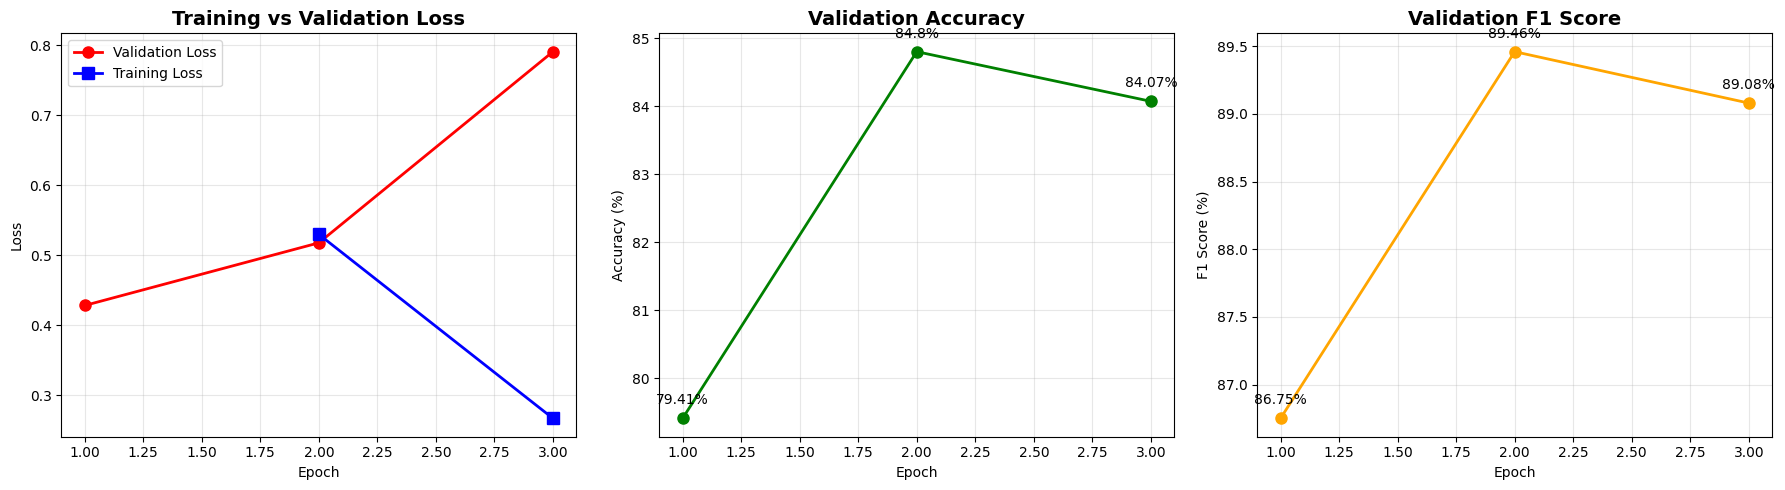

In [ ]:
import matplotlib.pyplot as plt
epochs = [1, 2, 3]
train_loss = [None, 0.5296, 0.2667]
val_loss = [0.4280, 0.5175, 0.7906]
accuracy = [79.41, 84.80, 84.07]
f1_score = [86.75, 89.46, 89.08]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#plot 1- Loss
axes[0].plot(epochs, val_loss, 'o-', color='red', label='Validation Loss', linewidth=2, markersize=8)
axes[0].plot([2, 3], [0.5296, 0.2667], 's-', color='blue', label='Training Loss', linewidth=2, markersize=8)
axes[0].set_title('Training vs Validation Loss', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

#plot 2- Accuracy
axes[1].plot(epochs, accuracy, 'o-', color='green', linewidth=2, markersize=8)
axes[1].set_title('Validation Accuracy', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].grid(True, alpha=0.3)
for i, v in enumerate(accuracy):
    axes[1].annotate(f'{v}%', (epochs[i], v), textcoords="offset points", xytext=(0, 10), ha='center')

#plot 3- F1 Score
axes[2].plot(epochs, f1_score, 'o-', color='orange', linewidth=2, markersize=8)
axes[2].set_title('Validation F1 Score', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('F1 Score (%)')
axes[2].grid(True, alpha=0.3)
for i, v in enumerate(f1_score):
    axes[2].annotate(f'{v}%', (epochs[i], v), textcoords="offset points", xytext=(0, 10), ha='center')

plt.tight_layout()
plt.savefig("training_metrics.png", dpi=150, bbox_inches='tight')
plt.show()